# Deep Q-Network (DQN) no Lunar Lander

Implementação de um agente DQN para o ambiente `LunarLander-v3` (Gymnasium), seguida de avaliação em teste, busca de hiperparâmetros e comparação com o Stable Baselines3.

In [16]:
#!pwd && ls -la
!pip install -r requirements.txt

  Using cached torch-2.15.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (36 kB)
  Using cached numpy-2.5.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached ipykernel-7.4.0-py3-none-any.whl.metadata (3.4 kB)
  Using cached cuda_toolkit-13.2.2-py2.py3-none-any.whl.metadata (20 kB)
  Using cached nvidia_cudnn_cu13-9.26.0.51-py3-none-manylinux_2_27_x86_64.whl.metadata (1.9 kB)
  Using cached nvidia_nvshmem_cu13-3.7.2-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (2.2 kB)
  Using cached triton-3.9.0-cp312-abi3-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (978 bytes)
  Using cached comm-0.2.3-py3-none-any.whl.metadata (3.7 kB)
  Using cached jupyter_client-8.10.0-py3-none-any.whl.metadata (8.5 kB)
  Using cached nest_asyncio2-1.7.4-py3-none-any.whl.metadata (7.0 kB)
  Using cached nvidia_cublas-13.4.1.3-py3-

In [17]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch
import torch.optim as optim
from collections import deque
import random


In [18]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, num_actions):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_actions),
        )

    def forward(self, state):
        return self.layers(state)

In [19]:
class DQNAgent:
    def __init__(
        self,
        observation_space,
        action_space,
        alpha,
        gamma,
        buffer_size,
        batch_size,
        target_update_interval,
        epsilon_initial,
        epsilon_decay,
        epsilon_min,
        device="cpu",
    ):
        self.observation_space = observation_space
        self.action_space = action_space

        self.state_dim = observation_space.shape[0]
        self.num_actions = action_space.n

        self.alpha = alpha
        self.gamma = gamma
        self.batch_size = batch_size
        self.target_update_interval = target_update_interval

        self.epsilon = epsilon_initial
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.buffer_size = buffer_size
        self._states = np.empty((buffer_size, self.state_dim), dtype=np.float32)
        self._actions = np.empty(buffer_size, dtype=np.int64)
        self._rewards = np.empty(buffer_size, dtype=np.float32)
        self._next_states = np.empty((buffer_size, self.state_dim), dtype=np.float32)
        self._terminals = np.empty(buffer_size, dtype=np.float32)
        self._buf_ptr = 0
        self._buf_size = 0

        self.device = torch.device(device)
        if self.device.type == "cpu":
            torch.set_num_threads(1)

        # rede principal e rede alvo começam com os mesmos pesos
        self.action_value = QNetwork(self.state_dim, self.num_actions).to(self.device)
        self.target = QNetwork(self.state_dim, self.num_actions).to(self.device)
        self.target.load_state_dict(self.action_value.state_dict())
        # não treinamos target diretamente, apenas atualizamos seus pesos com a action_value
        self.target.requires_grad_(False)
        self.target.eval()

        # apenas a rede principal é atualizada pelo otimizador
        self.optimizer = optim.Adam(self.action_value.parameters(), lr=self.alpha)
        self.loss_fn = nn.MSELoss()
        self.current_step = 0

    def choose_action(self, state, evaluate=False):
        if evaluate or random.random() >= self.epsilon:
            state_tensor = torch.as_tensor(state, dtype=torch.float32, device=self.device)
            with torch.no_grad():
                q_values = self.action_value(state_tensor)
            return q_values.argmax().item()

        return self.action_space.sample()

    def learn(self):
        if self._buf_size < self.batch_size:
            return
        idx = np.random.randint(0, self._buf_size, size=self.batch_size)

        states = torch.from_numpy(self._states[idx]).to(self.device)
        actions = torch.from_numpy(self._actions[idx]).to(self.device)
        rewards = torch.from_numpy(self._rewards[idx]).to(self.device)
        next_states = torch.from_numpy(self._next_states[idx]).to(self.device)
        terminals = torch.from_numpy(self._terminals[idx]).to(self.device)

        predictions = self.action_value(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        with torch.no_grad():
            max_next_q = self.target(next_states).max(dim=1).values
            targets = rewards + self.gamma * max_next_q * (1.0 - terminals)

        loss = self.loss_fn(predictions, targets)
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        self.optimizer.step()

    def train(self, env, episodes):
        self.training_returns = []
        rewards = self.training_returns

        for episode in range(episodes):
            state, _ = env.reset()
            done = False
            total_reward = 0

            while not done:
                action = self.choose_action(state)
                next_state, reward, terminated, truncated, info = env.step(action)
                self._states[self._buf_ptr] = state
                self._actions[self._buf_ptr] = action
                self._rewards[self._buf_ptr] = reward
                self._next_states[self._buf_ptr] = next_state
                self._terminals[self._buf_ptr] = float(terminated)
                self._buf_ptr = (self._buf_ptr + 1) % self.buffer_size
                if self._buf_size < self.buffer_size:
                    self._buf_size += 1
                self.learn()

                self.current_step += 1
                if self.current_step % self.target_update_interval == 0:
                    self.target.load_state_dict(self.action_value.state_dict())

                self.epsilon = max(self.epsilon_min, self.epsilon_decay * self.epsilon)

                state = next_state
                done = terminated or truncated
                total_reward += reward

            rewards.append(total_reward)

            if (episode + 1) % 10 == 0 or episode + 1 == episodes:
                recent_mean = np.mean(rewards[-100:])
                print(
                    f"Episódio {episode + 1}/{episodes} | "
                    f"média dos últimos {min(100, len(rewards))}: {recent_mean:.1f} | "
                    f"epsilon: {self.epsilon:.3f} | passos: {self.current_step}",
                    flush=True,
                )

        return rewards

    def evaluate(self, env, episodes=100, seed=None):
        was_training = self.action_value.training
        self.action_value.eval()
        rewards = []

        try:
            for episode in range(episodes):
                ep_seed = seed + episode if seed is not None else None
                state, _ = env.reset(seed=ep_seed)
                done = False
                total_reward = 0

                while not done:
                    action = self.choose_action(state, evaluate=True)
                    next_state, reward, terminated, truncated, _ = env.step(action)
                    state = next_state
                    done = terminated or truncated
                    total_reward += reward

                rewards.append(total_reward)
        finally:
            if was_training:
                self.action_value.train()

        return rewards

    def save(self, path):
        torch.save(self.action_value.state_dict(), path)

    def load(self, path):
        state_dict = torch.load(path, map_location=self.device, weights_only=True)
        self.action_value.load_state_dict(state_dict)
        self.target.load_state_dict(state_dict)

In [20]:
# Configuração inicial para os experimentos
import json
from pathlib import Path

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

env = gym.make("LunarLander-v3")
env.action_space.seed(seed)
env.reset(seed=seed)

baseline_model_path = Path("dqn_baseline.pt")
baseline_cache_path = Path("dqn_baseline_resultado.json")

try:
    dqn_agent = DQNAgent(
        env.observation_space,
        env.action_space,
        alpha=0.0003,
        gamma=0.99,
        buffer_size=50_000,
        batch_size=64,
        target_update_interval=1_000,  # Passos no ambiente.
        epsilon_initial=1.0,
        epsilon_decay=0.99995,  # Multiplicado a cada passo; mínimo em ~60 mil passos.
        epsilon_min=0.05,
    )

    print(f"Dispositivo de treinamento: {dqn_agent.device}", flush=True)
    if baseline_model_path.exists() and baseline_cache_path.exists():
        dqn_agent.load(str(baseline_model_path))
        with baseline_cache_path.open("r", encoding="utf-8") as f:
            dados_baseline = json.load(f)
        dqn_returns = dados_baseline["returns"]
        dqn_agent.training_returns = dqn_returns
        dqn_agent.current_step = dados_baseline["steps"]
        dqn_agent.epsilon = dados_baseline["epsilon"]
        print("Carregado do checkpoint: dqn_baseline", flush=True)
    else:
        dqn_returns = dqn_agent.train(env, episodes=2_000)
        dqn_agent.save(str(baseline_model_path))
        with baseline_cache_path.open("w", encoding="utf-8") as f:
            json.dump(
                {
                    "returns": [float(r) for r in dqn_returns],
                    "steps": int(dqn_agent.current_step),
                    "epsilon": float(dqn_agent.epsilon),
                },
                f,
                indent=2,
            )
finally:
    env.close()


ImportError: cannot import name 'get_current_stream' from 'torch._C._dynamo.utils' (unknown location)

Episódios: 2000
Retorno médio nos últimos 100 episódios: 270.67
Melhor retorno: 321.11
Retorno do último episódio: 263.22
Passos no ambiente: 631592
Epsilon final: 0.0500


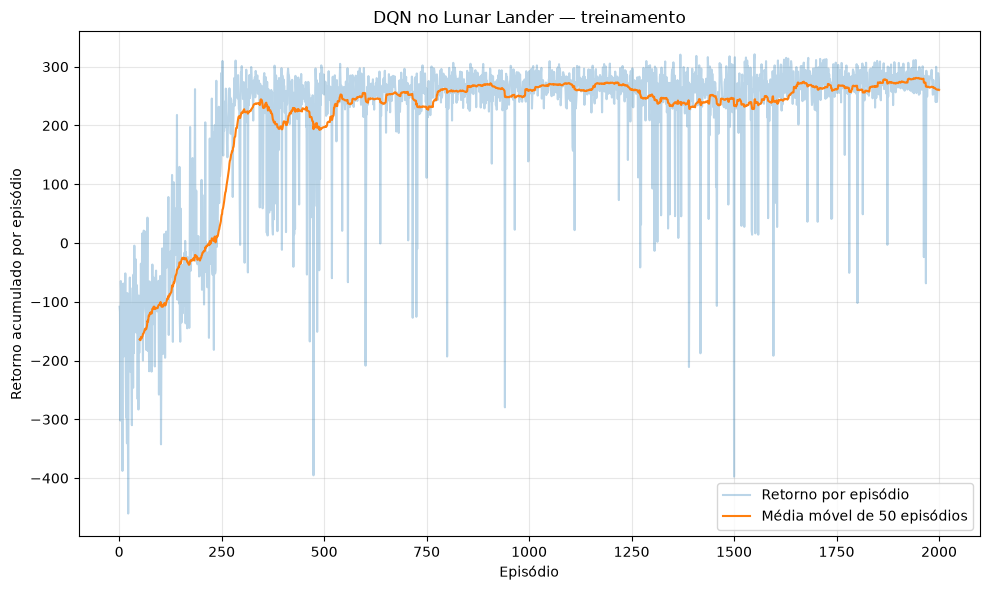

In [ ]:
# Resultados do treinamento (com exploração epsilon-greedy).
returns = np.asarray(dqn_returns, dtype=float)
last_n = min(100, len(returns))

print(f"Episódios: {len(returns)}")
print(f"Retorno médio nos últimos {last_n} episódios: {returns[-last_n:].mean():.2f}")
print(f"Melhor retorno: {returns.max():.2f}")
print(f"Retorno do último episódio: {returns[-1]:.2f}")
print(f"Passos no ambiente: {dqn_agent.current_step}")
print(f"Epsilon final: {dqn_agent.epsilon:.4f}")

window = min(50, len(returns))
episodes = np.arange(1, len(returns) + 1)
moving_average = np.convolve(returns, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(episodes, returns, alpha=0.3, label="Retorno por episódio")
ax.plot(episodes[window - 1:], moving_average,
        label=f"Média móvel de {window} episódios")
ax.set_title("DQN no Lunar Lander — treinamento")
ax.set_xlabel("Episódio")
ax.set_ylabel("Retorno acumulado por episódio")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
Path("graficos").mkdir(exist_ok=True)
fig.savefig("graficos/01_baseline_treinamento.png", dpi=150, bbox_inches="tight")
plt.show()


## Avaliação do Agente (Teste)

In [ ]:
test_env = gym.make("LunarLander-v3")

try:
    test_returns = np.asarray(
        dqn_agent.evaluate(test_env, episodes=100, seed=100),
        dtype=float,
    )
finally:
    test_env.close()

success_rate = np.mean(test_returns >= 200) * 100

print(f"Episódios de teste: {len(test_returns)}")
print(f"Retorno médio: {test_returns.mean():.2f} ± {test_returns.std():.2f}")
print(f"Mediana: {np.median(test_returns):.2f}")
print(f"Mínimo / Máximo: {test_returns.min():.2f} / {test_returns.max():.2f}")
print(f"Taxa de sucesso (>= 200): {success_rate:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

test_episodes = np.arange(1, len(test_returns) + 1)
axes[0].plot(test_episodes, test_returns, marker="o", markersize=3, alpha=0.7, label="Retorno")
axes[0].axhline(test_returns.mean(), color="tab:orange", linestyle="--", label=f"Média ({test_returns.mean():.1f})")
axes[0].axhline(200, color="tab:green", linestyle=":", label="Meta (200)")
axes[0].set_title("DQN no Lunar Lander — teste")
axes[0].set_xlabel("Episódio de teste")
axes[0].set_ylabel("Retorno acumulado")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(test_returns, bins=15, edgecolor="black", alpha=0.75)
axes[1].axvline(test_returns.mean(), color="tab:orange", linestyle="--", label=f"Média ({test_returns.mean():.1f})")
axes[1].axvline(200, color="tab:green", linestyle=":", label="Meta (200)")
axes[1].set_title("Distribuição dos retornos no teste")
axes[1].set_xlabel("Retorno acumulado")
axes[1].set_ylabel("Frequência")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
Path("graficos").mkdir(exist_ok=True)
fig.savefig("graficos/02_baseline_teste.png", dpi=150, bbox_inches="tight")
plt.show()

## Busca de Hiperparâmetros

A partir da configuração base usada acima, vamos variar um hiperparâmetro por vez para observar o efeito de cada um no aprendizado e no desempenho em teste:
- taxa de aprendizado (`alpha`);
- fator de desconto (`gamma`);
- tamanho do replay buffer (`buffer_size`);
- tamanho do batch (`batch_size`);
- frequência de atualização da rede alvo (`target_update_interval`);
- parâmetros da política $\varepsilon$-greedy (`epsilon_initial`, `epsilon_decay`, `epsilon_min`);
- número de episódios de treinamento (`episodes`).

Depois, treinamos a melhor configuração encontrada por mais episódios para comparar com o Stable Baselines3.

In [ ]:
import time


# Função para treinar e testar uma configuração mantendo as mesmas seeds
def rodar_experimento(
    nome,
    grupo,
    alpha=0.0003,
    gamma=0.99,
    buffer_size=50_000,
    batch_size=64,
    target_update_interval=1_000,
    epsilon_initial=1.0,
    epsilon_decay=0.99995,
    epsilon_min=0.05,
    episodes=1_000,
    eval_episodes=100,
    seed=42,
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make("LunarLander-v3")
    env.action_space.seed(seed)
    env.reset(seed=seed)

    inicio = time.time()
    try:
        agent = DQNAgent(
            env.observation_space,
            env.action_space,
            alpha=alpha,
            gamma=gamma,
            buffer_size=buffer_size,
            batch_size=batch_size,
            target_update_interval=target_update_interval,
            epsilon_initial=epsilon_initial,
            epsilon_decay=epsilon_decay,
            epsilon_min=epsilon_min,
        )
        train_returns = np.asarray(agent.train(env, episodes=episodes), dtype=float)
    finally:
        env.close()
    tempo_s = time.time() - inicio

    # Avalia a política aprendida sem exploração nos mesmos 100 episódios de teste
    test_env = gym.make("LunarLander-v3")
    try:
        test_returns = np.asarray(
            agent.evaluate(test_env, episodes=eval_episodes, seed=100),
            dtype=float,
        )
    finally:
        test_env.close()

    return {
        "nome": nome,
        "grupo": grupo,
        "params": {
            "alpha": alpha,
            "gamma": gamma,
            "buffer_size": buffer_size,
            "batch_size": batch_size,
            "target_update_interval": target_update_interval,
            "epsilon_initial": epsilon_initial,
            "epsilon_decay": epsilon_decay,
            "epsilon_min": epsilon_min,
            "episodes": episodes,
        },
        "train_returns": train_returns,
        "test_returns": test_returns,
        "train_last100": train_returns[-min(100, len(train_returns)):].mean(),
        "test_mean": test_returns.mean(),
        "test_std": test_returns.std(),
        "test_median": np.median(test_returns),
        "success_rate": np.mean(test_returns >= 200) * 100,
        "steps": agent.current_step,
        "tempo_s": tempo_s,
        "agent": agent,
    }

In [ ]:
# Configuração base para comparação na busca (1000 episódios para caber em tempo razoável)
import json
from pathlib import Path

config_base = {
    "alpha": 0.0003,
    "gamma": 0.99,
    "buffer_size": 50_000,
    "batch_size": 64,
    "target_update_interval": 1_000,
    "epsilon_initial": 1.0,
    "epsilon_decay": 0.99995,
    "epsilon_min": 0.05,
    "episodes": 1_000,
}

# Lista de experimentos variando um hiperparâmetro por vez
experimentos = [
    ("base_1000ep", "Referência", {}),
    ("alpha_0.0001", "alpha", {"alpha": 0.0001}),
    ("alpha_0.001", "alpha", {"alpha": 0.001}),
    ("gamma_0.95", "gamma", {"gamma": 0.95}),
    ("gamma_0.995", "gamma", {"gamma": 0.995}),
    ("buffer_10k", "buffer_size", {"buffer_size": 10_000}),
    ("buffer_100k", "buffer_size", {"buffer_size": 100_000}),
    ("batch_32", "batch_size", {"batch_size": 32}),
    ("batch_128", "batch_size", {"batch_size": 128}),
    ("target_250", "target_update", {"target_update_interval": 250}),
    ("target_2500", "target_update", {"target_update_interval": 2_500}),
    ("eps_decay_0.9995", "epsilon", {"epsilon_decay": 0.9995}),
    ("eps_decay_0.99998", "epsilon", {"epsilon_decay": 0.99998}),
    ("eps_min_0.01", "epsilon", {"epsilon_min": 0.01}),
    ("eps_init_0.5", "epsilon", {"epsilon_initial": 0.5}),
    ("ep_500", "episodes", {"episodes": 500}),
    ("ep_2000", "episodes", {"episodes": 2_000}),
]

checkpoint_path = Path("resultados_busca.json")
modelos_dir = Path("modelos_busca")
modelos_dir.mkdir(exist_ok=True)

cache_busca = {}
if checkpoint_path.exists():
    with checkpoint_path.open("r", encoding="utf-8") as f:
        dados_salvos = json.load(f)
    for nome_salvo, entry in dados_salvos.items():
        entry["train_returns"] = np.asarray(entry["train_returns"], dtype=float)
        entry["test_returns"] = np.asarray(entry["test_returns"], dtype=float)
        cache_busca[nome_salvo] = entry

def salvar_checkpoint_busca(cache, path):
    serializavel = {}
    for k, v in cache.items():
        serializavel[k] = {
            "nome": v["nome"],
            "grupo": v["grupo"],
            "params": v["params"],
            "train_returns": np.asarray(v["train_returns"], dtype=float).tolist(),
            "test_returns": np.asarray(v["test_returns"], dtype=float).tolist(),
            "train_last100": float(v["train_last100"]),
            "test_mean": float(v["test_mean"]),
            "test_std": float(v["test_std"]),
            "test_median": float(v["test_median"]),
            "success_rate": float(v["success_rate"]),
            "steps": int(v["steps"]),
            "tempo_s": float(v["tempo_s"]),
            "model_path": v.get("model_path"),
        }
    with path.open("w", encoding="utf-8") as f:
        json.dump(serializavel, f, indent=2, ensure_ascii=False)

resultados_busca = []

for idx, (nome, grupo, ajustes) in enumerate(experimentos, start=1):
    params = dict(config_base)
    params.update(ajustes)
    if nome in cache_busca and cache_busca[nome].get("params") == params:
        res = cache_busca[nome]
        resultados_busca.append(res)
        print(
            f"\n[{idx}/{len(experimentos)}] Carregado do checkpoint: {nome} | "
            f"teste: {res['test_mean']:.1f} ± {res['test_std']:.1f} | "
            f"sucesso (>=200): {res['success_rate']:.1f}%",
            flush=True,
        )
        continue

    print(f"\n[{idx}/{len(experimentos)}] Rodando experimento: {nome} -> {ajustes or 'config_base'}", flush=True)
    res = rodar_experimento(nome, grupo, **params)
    model_path = modelos_dir / f"{nome}.pt"
    res["agent"].save(str(model_path))
    res["model_path"] = str(model_path)
    cache_busca[nome] = res
    salvar_checkpoint_busca(cache_busca, checkpoint_path)
    resultados_busca.append(res)
    print(
        f"Fim {nome} | teste: {res['test_mean']:.1f} ± {res['test_std']:.1f} | "
        f"sucesso (>=200): {res['success_rate']:.1f}% | tempo: {res['tempo_s']:.1f}s",
        flush=True,
    )

# Resumo em tabela simples para facilitar a análise
print("\n" + "-" * 106)
print(
    f"{'Experimento':<20} {'Grupo':<14} {'Treino(100)':>11} {'Teste Média±DP':>18} "
    f"{'Mediana':>9} {'Sucesso':>9} {'Passos':>10} {'Tempo(s)':>9}"
)
print("-" * 106)
for r in resultados_busca:
    teste_str = f"{r['test_mean']:.1f} ± {r['test_std']:.1f}"
    print(
        f"{r['nome']:<20} {r['grupo']:<14} {r['train_last100']:>11.1f} {teste_str:>18} "
        f"{r['test_median']:>9.1f} {r['success_rate']:>8.1f}% {r['steps']:>10} {r['tempo_s']:>9.1f}"
    )
print("-" * 106)

melhor_busca = max(resultados_busca, key=lambda r: (r["success_rate"], r["test_mean"]))
print(f"\nMelhor resultado da busca: {melhor_busca['nome']} (sucesso: {melhor_busca['success_rate']:.1f}%, média: {melhor_busca['test_mean']:.2f})")

In [ ]:
# Curvas de treinamento agrupadas por hiperparâmetro
grupos = ["alpha", "gamma", "buffer_size", "batch_size", "target_update", "epsilon", "episodes"]
base_res = resultados_busca[0]  # base_1000ep

def media_movel(valores, janela=50):
    w = min(janela, len(valores))
    return np.convolve(valores, np.ones(w) / w, mode="valid"), w

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes_flat = axes.flat

for ax, grupo in zip(axes_flat, grupos):
    # Plota a referência em todos os subplots para facilitar a comparação
    mm_base, w_base = media_movel(base_res["train_returns"])
    ax.plot(np.arange(w_base, len(base_res["train_returns"]) + 1), mm_base,
            linestyle="--", color="black", label=base_res["nome"])

    for r in resultados_busca:
        if r["grupo"] == grupo:
            mm, w = media_movel(r["train_returns"])
            ax.plot(np.arange(w, len(r["train_returns"]) + 1), mm, label=r["nome"])

    ax.axhline(200, color="tab:green", linestyle=":", alpha=0.7)
    ax.set_title(f"Impacto de {grupo} no treinamento")
    ax.set_xlabel("Episódio")
    ax.set_ylabel("Média móvel (50 ep.)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Esconde o último subplot que sobrou no grid 4x2
axes_flat[7].axis("off")
fig.tight_layout()
Path("graficos").mkdir(exist_ok=True)
fig.savefig("graficos/03_busca_curvas_treinamento.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparação do desempenho no teste (100 episódios) entre todas as configurações
nomes = [r["nome"] for r in resultados_busca]
medias_teste = [r["test_mean"] for r in resultados_busca]
desvios_teste = [r["test_std"] for r in resultados_busca]
taxas_sucesso = [r["success_rate"] for r in resultados_busca]
y_pos = np.arange(len(nomes))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].barh(y_pos, medias_teste, xerr=desvios_teste, alpha=0.8, capsize=3)
axes[0].axvline(200, color="tab:green", linestyle=":", label="Meta (200)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(nomes)
axes[0].invert_yaxis()
axes[0].set_title("Retorno médio no teste (± desvio padrão)")
axes[0].set_xlabel("Retorno acumulado")
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis="x")

axes[1].barh(y_pos, taxas_sucesso, color="tab:orange", alpha=0.8)
axes[1].set_title("Taxa de sucesso no teste (>= 200)")
axes[1].set_xlabel("Taxa de sucesso (%)")
axes[1].set_xlim(0, 105)
axes[1].grid(True, alpha=0.3, axis="x")

fig.tight_layout()
fig.savefig("graficos/04_busca_comparacao_teste.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Treinamento final com a melhor configuração da busca (garantindo pelo menos 2000 episódios)
# Se quiser testar uma combinação manual depois de olhar os gráficos, basta editar os valores aqui.
import json
import shutil
from pathlib import Path

melhor_config = dict(melhor_busca["params"])
melhor_config["episodes"] = max(2_000, melhor_config["episodes"])

print("Configuração final escolhida para o nosso DQN:")
print(melhor_config)

melhor_model_path = Path("dqn_melhor.pt")
melhor_cache_path = Path("dqn_melhor_resultado.json")
carregado_melhor = False

if melhor_busca["params"] == melhor_config:
    res_melhor = melhor_busca
    dqn_melhor = res_melhor.get("agent")
    if dqn_melhor is not None:
        dqn_melhor.save(str(melhor_model_path))
    elif res_melhor.get("model_path") and Path(res_melhor["model_path"]).exists():
        shutil.copyfile(res_melhor["model_path"], str(melhor_model_path))
    print(f"Reaproveitando modelo já treinado da busca: {melhor_busca['nome']}")
else:
    if melhor_model_path.exists() and melhor_cache_path.exists():
        with melhor_cache_path.open("r", encoding="utf-8") as f:
            dados_melhor = json.load(f)
        if dados_melhor.get("params") == melhor_config:
            dados_melhor["train_returns"] = np.asarray(dados_melhor["train_returns"], dtype=float)
            dados_melhor["test_returns"] = np.asarray(dados_melhor["test_returns"], dtype=float)
            res_melhor = dados_melhor
            dqn_melhor = None
            carregado_melhor = True
            print("Carregado do checkpoint: dqn_melhor")
    if not carregado_melhor:
        res_melhor = rodar_experimento("dqn_melhor", "Final", **melhor_config)
        dqn_melhor = res_melhor["agent"]
        dqn_melhor.save(str(melhor_model_path))

if not carregado_melhor:
    with melhor_cache_path.open("w", encoding="utf-8") as f:
        json.dump(
            {
                "nome": res_melhor["nome"],
                "grupo": res_melhor["grupo"],
                "params": res_melhor["params"],
                "train_returns": np.asarray(res_melhor["train_returns"], dtype=float).tolist(),
                "test_returns": np.asarray(res_melhor["test_returns"], dtype=float).tolist(),
                "train_last100": float(res_melhor["train_last100"]),
                "test_mean": float(res_melhor["test_mean"]),
                "test_std": float(res_melhor["test_std"]),
                "test_median": float(res_melhor["test_median"]),
                "success_rate": float(res_melhor["success_rate"]),
                "steps": int(res_melhor["steps"]),
                "tempo_s": float(res_melhor["tempo_s"]),
                "model_path": str(melhor_model_path),
            },
            f,
            indent=2,
            ensure_ascii=False,
        )

melhor_test_returns = res_melhor["test_returns"]
print(f"\nEpisódios de teste: {len(melhor_test_returns)}")
print(f"Retorno médio: {res_melhor['test_mean']:.2f} ± {res_melhor['test_std']:.2f}")
print(f"Mediana: {res_melhor['test_median']:.2f}")
print(f"Mínimo / Máximo: {melhor_test_returns.min():.2f} / {melhor_test_returns.max():.2f}")
print(f"Taxa de sucesso (>= 200): {res_melhor['success_rate']:.1f}%")
print(f"Passos no treino: {res_melhor['steps']} | Tempo: {res_melhor['tempo_s']:.1f}s")

## Comparação com o Stable Baselines3

Agora vamos treinar a implementação padrão de `DQN` da biblioteca Stable Baselines3 (`MlpPolicy`, sem alterar os hiperparâmetros padrão) usando a mesma quantidade de passos de interação com o ambiente, e depois avaliar nos mesmos 100 episódios de teste (`seed=100`).

In [ ]:
# Instala o stable-baselines3 caso ainda não esteja disponível no ambiente
import json
from pathlib import Path
import shutil
import subprocess
import sys

try:
    from stable_baselines3 import DQN as SB3_DQN
    from stable_baselines3.common.monitor import Monitor
except ImportError:
    if shutil.which("uv"):
        subprocess.check_call(["uv", "pip", "install", "stable-baselines3"])
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "stable-baselines3"])
    from stable_baselines3 import DQN as SB3_DQN
    from stable_baselines3.common.monitor import Monitor

sb3_seed = 42
total_passos_sb3 = res_melhor["steps"]

sb3_model_path = Path("dqn_sb3.zip")
sb3_cache_path = Path("dqn_sb3_resultado.json")
carregado_sb3 = False

if sb3_model_path.exists() and sb3_cache_path.exists():
    with sb3_cache_path.open("r", encoding="utf-8") as f:
        dados_sb3 = json.load(f)
    if dados_sb3.get("steps") == total_passos_sb3:
        sb3_model = SB3_DQN.load("dqn_sb3", device="cpu")
        sb3_train_returns = np.asarray(dados_sb3["train_returns"], dtype=float)
        sb3_test_returns = np.asarray(dados_sb3["test_returns"], dtype=float)
        tempo_sb3 = float(dados_sb3["tempo_s"])
        sb3_success_rate = float(dados_sb3["success_rate"])
        carregado_sb3 = True
        print("Carregado do checkpoint: dqn_sb3")

if not carregado_sb3:
    # O Monitor guarda o retorno de cada episódio concluído durante o treino do SB3
    sb3_env = Monitor(gym.make("LunarLander-v3"))
    sb3_env.reset(seed=sb3_seed)

    inicio_sb3 = time.time()
    try:
        sb3_model = SB3_DQN("MlpPolicy", sb3_env, seed=sb3_seed, device="cpu", verbose=1)
        sb3_model.learn(total_timesteps=total_passos_sb3, log_interval=50)
        sb3_train_returns = np.asarray(sb3_env.get_episode_rewards(), dtype=float)
    finally:
        sb3_env.close()
    tempo_sb3 = time.time() - inicio_sb3

    sb3_model.save("dqn_sb3")

    # Avaliação do modelo do SB3 exatamente nos mesmos 100 episódios de teste
    sb3_test_env = gym.make("LunarLander-v3")
    sb3_test_returns = []

    try:
        for episode in range(100):
            state, _ = sb3_test_env.reset(seed=100 + episode)
            done = False
            total_reward = 0.0

            while not done:
                action, _ = sb3_model.predict(state, deterministic=True)
                next_state, reward, terminated, truncated, _ = sb3_test_env.step(int(action))
                state = next_state
                done = terminated or truncated
                total_reward += reward

            sb3_test_returns.append(total_reward)
    finally:
        sb3_test_env.close()

    sb3_test_returns = np.asarray(sb3_test_returns, dtype=float)
    sb3_success_rate = np.mean(sb3_test_returns >= 200) * 100

    with sb3_cache_path.open("w", encoding="utf-8") as f:
        json.dump(
            {
                "steps": int(total_passos_sb3),
                "tempo_s": float(tempo_sb3),
                "train_returns": sb3_train_returns.tolist(),
                "test_returns": sb3_test_returns.tolist(),
                "success_rate": float(sb3_success_rate),
            },
            f,
            indent=2,
        )

print(f"\nEpisódios de treino (SB3): {len(sb3_train_returns)} | Passos: {total_passos_sb3} | Tempo: {tempo_sb3:.1f}s")
print(f"Teste SB3 — Média: {sb3_test_returns.mean():.2f} ± {sb3_test_returns.std():.2f}")
print(f"Teste SB3 — Mediana: {np.median(sb3_test_returns):.2f}")
print(f"Teste SB3 — Mín / Máx: {sb3_test_returns.min():.2f} / {sb3_test_returns.max():.2f}")
print(f"Teste SB3 — Taxa de sucesso (>= 200): {sb3_success_rate:.1f}%")

In [ ]:
# Comparativo direto: Nosso DQN (melhor config) vs. Stable Baselines3 (padrão)
print(f"{'Métrica':<28} {'Nosso DQN':>18} {'SB3 (padrão)':>18}")
print("-" * 66)
print(f"{'Episódios de treino':<28} {len(res_melhor['train_returns']):>18} {len(sb3_train_returns):>18}")
print(f"{'Passos no ambiente':<28} {res_melhor['steps']:>18} {total_passos_sb3:>18}")
print(f"{'Tempo de treino (s)':<28} {res_melhor['tempo_s']:>18.1f} {tempo_sb3:>18.1f}")
print(f"{'Média no teste':<28} {res_melhor['test_mean']:>18.2f} {sb3_test_returns.mean():>18.2f}")
print(f"{'Desvio padrão no teste':<28} {res_melhor['test_std']:>18.2f} {sb3_test_returns.std():>18.2f}")
print(f"{'Mediana no teste':<28} {res_melhor['test_median']:>18.2f} {np.median(sb3_test_returns):>18.2f}")
print(f"{'Mínimo no teste':<28} {melhor_test_returns.min():>18.2f} {sb3_test_returns.min():>18.2f}")
print(f"{'Máximo no teste':<28} {melhor_test_returns.max():>18.2f} {sb3_test_returns.max():>18.2f}")
print(f"{'Taxa de sucesso (>= 200)':<28} {res_melhor['success_rate']:>17.1f}% {sb3_success_rate:>17.1f}%")

# Gráfico 1: evolução durante o treinamento (média móvel de 50 episódios)
fig, ax = plt.subplots(figsize=(10, 5))

mm_nosso, w1 = media_movel(res_melhor["train_returns"], janela=50)
ax.plot(np.arange(w1, len(res_melhor["train_returns"]) + 1), mm_nosso, label="Nosso DQN (média móvel 50 ep.)")

if len(sb3_train_returns) >= 50:
    mm_sb3, w2 = media_movel(sb3_train_returns, janela=50)
    ax.plot(np.arange(w2, len(sb3_train_returns) + 1), mm_sb3, label="SB3 DQN padrão (média móvel 50 ep.)")
else:
    ax.plot(np.arange(1, len(sb3_train_returns) + 1), sb3_train_returns, label="SB3 DQN padrão")

ax.axhline(200, color="tab:green", linestyle=":", label="Meta (200)")
ax.set_title("Comparação no treinamento — Nosso DQN vs. Stable Baselines3")
ax.set_xlabel("Episódio")
ax.set_ylabel("Retorno acumulado")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
Path("graficos").mkdir(exist_ok=True)
fig.savefig("graficos/05_comparacao_sb3_treinamento.png", dpi=150, bbox_inches="tight")
plt.show()

# Gráfico 2: comparação dos 100 episódios de teste
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ep_teste = np.arange(1, 101)
axes[0].plot(ep_teste, melhor_test_returns, marker="o", markersize=3, alpha=0.7, label="Nosso DQN")
axes[0].plot(ep_teste, sb3_test_returns, marker="x", markersize=3, alpha=0.7, label="SB3 padrão")
axes[0].axhline(200, color="tab:green", linestyle=":", label="Meta (200)")
axes[0].set_title("Retorno por episódio de teste")
axes[0].set_xlabel("Episódio de teste")
axes[0].set_ylabel("Retorno acumulado")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].boxplot([melhor_test_returns, sb3_test_returns], tick_labels=["Nosso DQN", "SB3 padrão"])
axes[1].axhline(200, color="tab:green", linestyle=":", label="Meta (200)")
axes[1].set_title("Distribuição dos retornos no teste")
axes[1].set_ylabel("Retorno acumulado")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("graficos/06_comparacao_sb3_teste.png", dpi=150, bbox_inches="tight")
plt.show()